# XS-GEM5 Tutorial 总览

本次 XS-GEM5 tutorial 将围绕 XS-GEM5 的编译、运行、性能分析和优化展开。内容包括：

- 编译并准备 XS-GEM5 及其运行所需的预编译资源；
- 使用 `kmhv3.py` 运行 RISC-V workload，完成基本的 XS-GEM5 仿真；
- 利用 XS-GEM5 平台的性能分析工具，从 Top-Down、PerfCCT 和指令时间线等角度分析 `memcpy` 的性能瓶颈；
- 通过开启默认预取器以及实现 L2 next-line prefetcher，验证并优化 `memcpy` 带宽。

下面按 01-04 的顺序完整保留教程内容和已生成的输出，可直接用于现场讲解，无需现场重新运行。

# 01-编译 XS-GEM5

在上手环节的整个过程中，大家如果有问题可以举手示意，我们的小伙伴会帮助大家。

本 tutorial 固定使用 OpenXiangShan/GEM5 提交 `8eecd224437707c4c5199bcd49ceca4a15ef8e4a`，确保各位听众看到的配置、DRAMSim3 和 PerfCCT 行为都一致。为了节约时间，现场实验直接使用预编译的 `gem5.fast`。

常规 GEM5 开发和调试通常编译 `gem5.opt`，它包含更多调试信息，便于定位问题。本次演示使用 `gem5.fast`，功能满足当前实验需求，但体积更小、运行更快，更适合分发和课堂演示。

本次实验使用的源码版本和三个运行资产如下。

In [9]:
%%bash
source ../env.sh

git -C "$GEM5_HOME" log -1 --format='GEM5 commit: %H%nSubject: %s'
printf '\nPre-compiled assets:\n'
ASSET=$(get_asset gem5-precompile)
for name in gem5.fast libdramsim3.so riscv64-nemu-interpreter-so; do
  printf '  %s\n' "$ASSET/$name"
done

GEM5 commit: 8eecd224437707c4c5199bcd49ceca4a15ef8e4a
Subject: mem-cache: Add tutorial L2 next-line prefetcher

Pre-compiled assets:
  /nfs/home/lixin/myworkspace/bootcamp/assets/gem5-precompile/gem5.fast
  /nfs/home/lixin/myworkspace/bootcamp/assets/gem5-precompile/libdramsim3.so
  /nfs/home/lixin/myworkspace/bootcamp/assets/gem5-precompile/riscv64-nemu-interpreter-so


- `gem5.fast`：后续 tutorial 02--04 实际运行的模拟器；
- `libdramsim3.so`：GEM5 运行时加载的 DRAMSim3 动态库；
- `riscv64-nemu-interpreter-so`：difftest 使用的 NEMU reference。

演示过程中不现场编译。下面的命令全部以 `#` 注释保留，供需要修改 GEM5 源码的听众复现。

In [10]:
%%bash
# 下面仅展示编译流程；这个单元不会执行任何命令。

# source ../env.sh
#
# # 使用 tutorial 固定的 GEM5 源码版本。
# cd "$GEM5_HOME"
# git checkout 8eecd224437707c4c5199bcd49ceca4a15ef8e4a
#
# # 首次编译时准备 DRAMSim3。init.sh 会下载并编译共享库。
# bash ./init.sh
#
# # --linker=mold 是可选的，可以加速编译过程，需要事先安装 mold 链接器，我们提供的 code-server 镜像中已经包含。
# # 常规开发和调试通常编译 gem5.opt，它包含更多调试信息：
# scons build/RISCV/gem5.opt --linker=mold -j8
#
# # 本次演示使用体积更小、运行更快的 gem5.fast：
# # scons build/RISCV/gem5.fast --linker=mold -j8
#
# # 运行时让动态链接器能够找到刚才构建的 DRAMSim3。
# export LD_LIBRARY_PATH="$GEM5_HOME/ext/dramsim3/DRAMsim3:${LD_LIBRARY_PATH:-}"
# ./build/RISCV/gem5.opt --help

编译完成后，演示使用的模拟器会位于 `GEM5/build/RISCV/gem5.opt`，DRAMSim3 动态库位于 `GEM5/ext/dramsim3/DRAMsim3/libdramsim3.so`。本 tutorial 已把这些运行所需文件打包进 `assets/gem5-precompile`。

# 02-First run：用 kmhv3.py 运行 hello

这一节建立最基本的运行方式：`kmhv3.py` 创建香山处理器和存储系统，`--raw-cpt` 表示输入不是切片，是普通 workload，`--generic-rv-cpt` 指向要执行的 RISC-V 程序。

我们直接使用 01 中的预编译 GEM5，运行一个 hello 程序。

## 运行 hello

In [9]:
%%bash
set -euo pipefail
source ../env.sh

RUN="$WORK_DIR/04-gem5/02-first-run/precompiled"
rm -rf "$RUN/m5out"
mkdir -p "$RUN"

# 我们提供的 GEM5 模拟器 或 01 中编译好的 GEM5 模拟器
GEM5_BIN=$(get_asset gem5-precompile/gem5.fast)
# 即将运行的 hello 程序的 bin 文件
HELLO=$(get_asset workload/hello-riscv64-xs.bin)
# 让 GEM5 能够找到 DramSim3 库
export LD_LIBRARY_PATH="$(get_asset gem5-precompile):${LD_LIBRARY_PATH:-}"
# 与 GEM5 在线 difftest 的 nemu
export GCBV_REF_SO=$(get_asset gem5-precompile/riscv64-nemu-interpreter-so)

cd "$GEM5_HOME"

# 使用 --raw-cpt 参数来执行非切片程序，若是切片程序则不需要这个参数
"$GEM5_BIN" --outdir="$RUN/m5out" \
  "$GEM5_HOME/configs/example/kmhv3.py" \
  --raw-cpt --generic-rv-cpt="$HELLO" \
  2>&1 | tee "$RUN/run.log" >/dev/null

tr '\r' '\n' < "$RUN/run.log"

gem5 Simulator System.  https://www.gem5.org
gem5 is copyrighted software; use the --copyright option for details.

gem5 version [DEVELOP-FOR-22.1]
gem5 compiled Oct 15 2026 10:15:43
gem5 started Oct 15 2026 18:38:34
gem5 executing on node032.bosccluster.com, pid 1246937
command line: /nfs/home/lixin/myworkspace/bootcamp/assets/gem5-precompile/gem5.fast --outdir=/nfs/home/lixin/myworkspace/bootcamp/work/04-gem5/02-first-run/precompiled/m5out /nfs/home/lixin/myworkspace/bootcamp/GEM5/configs/example/kmhv3.py --raw-cpt --generic-rv-cpt=/nfs/home/lixin/myworkspace/bootcamp/assets/workload/hello-riscv64-xs.bin

info: Standard input is not a terminal, disabling listeners.
Checkpoint mode: Using standard FS mode with normal MMU translation
Obtained ref_so from GCBV_REF_SO:  /nfs/home/lixin/myworkspace/bootcamp/assets/gem5-precompile/riscv64-nemu-interpreter-so
Simulating single core without RVV, demanding GCPT restorer size of 0x700.
Using raw bbl /nfs/home/lixin/myworkspace/bootcamp/assets/

这里我们通过这一段bash脚本，XS-GEM5运行hello word。运行结束之后可以输出“Hello，Xiangshan!”

最后的 `m5_exit` 表示 guest 主动结束模拟。

# 03-性能分析流程：改善 memcpy 的带宽

本节使用一个 512 KiB memcpy 完成一次性能分析闭环：

1. 关闭预取，观察 memcpy 带宽；
2. 用 Top-Down 计数器观察处理器瓶颈；
3. 使用 PerfCCT，可视化每一条指令的执行并抓取热点循环；
4. 开启 KMHv3 默认预取，与关闭预取的 memcpy 带宽进行对比，确认性能收益来源。

## 1. 工作负载：512 KiB memcpy

memcpy workload：将一段数据从某一块内存区域复制到另一块内存区域。

In [94]:
%%bash
source ../env.sh
ASSET=$(get_asset workload)
ls -lh "$ASSET/gem5-memcpy-riscv64-xs.bin" "$ASSET/gem5-memcpy-riscv64-xs.txt"

-rwxr-xr-x 1 lixin kunminghu 1.1M Oct 13 19:33 /nfs/home/lixin/myworkspace/bootcamp/assets/workload/gem5-memcpy-riscv64-xs.bin
-rw-r--r-- 1 lixin kunminghu  87K Oct 13 19:33 /nfs/home/lixin/myworkspace/bootcamp/assets/workload/gem5-memcpy-riscv64-xs.txt


## 1. 关闭预取的 kmhv3 GEM5 模型运行 memcpy

In [95]:
%%bash
set -euo pipefail
source ../env.sh

RUN="$WORK_DIR/04-gem5/03-perf/no-prefetch"
mkdir -p "$RUN"
rm -rf "$RUN/m5out"
GEM5_BIN=$(get_asset gem5-precompile/gem5.fast)
# memcpy workload 的 bin 文件
MEMCPY=$(get_asset workload/gem5-memcpy-riscv64-xs.bin)
export LD_LIBRARY_PATH="$(get_asset gem5-precompile):${LD_LIBRARY_PATH:-}"
export GCBV_REF_SO=$(get_asset gem5-precompile/riscv64-nemu-interpreter-so)
cd "$GEM5_HOME"

# 使用 --no-pf 参数来关闭 prefetcher
"$GEM5_BIN" --outdir="$RUN/m5out" \
  "$GEM5_HOME/configs/example/kmhv3.py" \
  --raw-cpt --generic-rv-cpt="$MEMCPY" --no-pf \
  2>&1 | tee "$RUN/run.log" >/dev/null

cat "$RUN/run.log" | tail -n 20

Registering probe listeners for BaseO3CPU system.cpu
Registering inner cache accessors for L2CacheWrapper system.l2_wrappers
Registering inner cache accessor for L2CacheSlice system.l2_wrappers.slices0
Registering inner cache accessor for L2CacheSlice system.l2_wrappers.slices1
Registering inner cache accessor for L2CacheSlice system.l2_wrappers.slices2
Registering inner cache accessor for L2CacheSlice system.l2_wrappers.slices3
build/RISCV/mem/physical.cc:509: warn: Unserializing physical memory from file /nfs/home/lixin/myworkspace/bootcamp/assets/workload/gem5-memcpy-riscv64-xs.bin
build/RISCV/mem/physical.cc:580: info: copying /nfs/home/lixin/myworkspace/bootcamp/assets/workload/gem5-memcpy-riscv64-xs.bin to pmem 0x7421e1600000
build/RISCV/mem/physical.cc:610: info: First 4 bytes are 0x93 0x0 0x0 0x0
build/RISCV/sim/system.cc:561: info: Restored from Xiangshan RISC-V Checkpoint
**** REAL SIMULATION ****
build/RISCV/sim/simulate.cc:194: info: Entering event queue @ 0.  Starting simu

从结果上可以看到，关闭预取的 kmhv3 GEM5 模型的 memcpy 搬运数据的速度在 5076.06 MiB/s 左右

## 2. Top-Down：先判断瓶颈属于哪一侧

In [96]:
%%bash
set -euo pipefail
source ../env.sh

RUN="$WORK_DIR/04-gem5/03-perf/no-prefetch"
INPUT="$RUN/topdown-input"
mkdir -p "$INPUT"
ln -sfn "$RUN/m5out" "$INPUT/current"

# 使用 gem5_data_proc 处理 topdown 数据
# -t --topdown-raw 参数指示 gem5_data_proc 处理 topdown 数据
export PYTHONPATH="$GEM5_DATA_PROC_HOME"
python3 "$GEM5_DATA_PROC_HOME/batch.py" \
  -s "$INPUT" -t --topdown-raw \
  -o "$RUN/topdown-raw.csv" \
  > "$RUN/topdown.log"

printf 'Top-Down data: %s\n' "$RUN/topdown-raw.csv"

Top-Down data: /nfs/home/lixin/myworkspace/bootcamp/work/04-gem5/03-perf/no-prefetch/topdown-raw.csv


使用 `gem5_data_proc` 仓库下的脚本来，处理得到关闭预取后 m5out 目录，得到 topdown 原始数据

In [97]:
%%bash
set -euo pipefail
source ../env.sh

RUN="$WORK_DIR/04-gem5/03-perf/no-prefetch"
cat "$RUN/topdown-raw.csv"

,Atomic,BpStall,CommitSquash,Cycles,DTlbStall,FetchBufferInvalid,ITlbStall,IcacheStall,InstMisPred,InstNotReady,InstSquashed,Insts,IntStall,LoadL1Bound,LoadL2Bound,LoadL3Bound,LoadMemBound,MemCommitRateLimit,MemNotReady,MemSquashed,NoStall,OtherFetchStall,OtherMemStall,OtherStall,ResumeUnblock,SerializeStall,SquashStall,StoreL1Bound,StoreL2Bound,StoreL3Bound,StoreMemBound,TrapStall,bmk,ipc,point,workload
current_0,0,0,1544,708809,0,0,0,1246,0,4714,36007,168700,0,479294,637041,68,1094703,0,141215,0,1511134,0,28,0,0,296,0,71319,0,0,0,0,current,0.238005,0,current


运行以下脚本，将以上原始 topdown 数据进行加工，便于阅读

,percent
Retiring,37.98
Frontend,0.03
Bad speculation,0.94
Memory,60.92
Core/other,0.13


,percent
L1,22.72
L2,26.28
L3,0.00
DRAM,45.17
TLB,0.00
Waiting/other,5.83


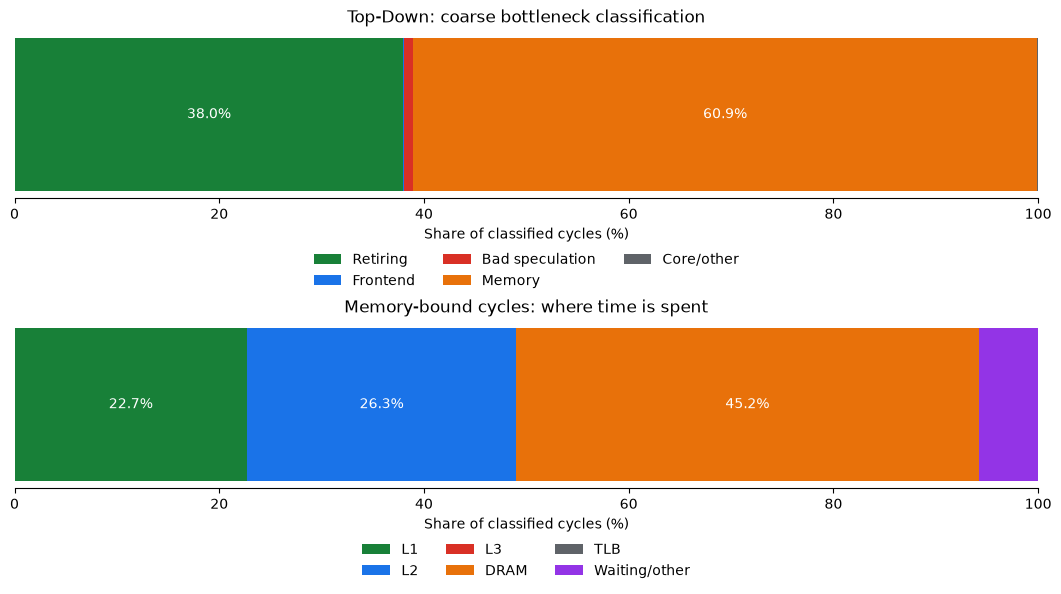

In [98]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()
if not (ROOT / "GEM5").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "04-gem5"))

from gem5_tutorial_utils import plot_topdown
fig, (level1, memory) = plot_topdown(
    ROOT / "work/04-gem5/03-perf/no-prefetch/topdown-raw.csv"
)
display(level1.round(2).to_frame("percent"))
display(memory.round(2).to_frame("percent"))
plt.show()

Top-Down 可以回答宏观问题：执行时间主要消耗在前端、错误推测、核心执行还是内存侧。这里我们可以确认是 memory-bound，接下来我们使用 PerfCCT 工具来深入分析。

## 3. PerfCCT：指令生命周期与热点循环提取

PerfCCT 工具的原理：将每一条被 **Rob Commit** 的指令的在乱序执行的各个生命周期时刻（例如：取值、译码、重命名、执行、写回等）记录到数据库中

In [99]:
%%bash
set -euo pipefail
source ../env.sh

RUN="$WORK_DIR/04-gem5/03-perf/no-prefetch-perfcct"
mkdir -p "$RUN"
rm -rf "$RUN/m5out"
rm -f "$RUN/perfcct.db"
GEM5_BIN=$(get_asset gem5-precompile/gem5.fast)
MEMCPY=$(get_asset workload/gem5-memcpy-riscv64-xs.bin)
export LD_LIBRARY_PATH="$(get_asset gem5-precompile):${LD_LIBRARY_PATH:-}"
export GCBV_REF_SO=$(get_asset gem5-precompile/riscv64-nemu-interpreter-so)
cd "$GEM5_HOME"

# 使用 --enable-arch-db --arch-db-dump-lifetime 开启 perfcct 数据库的生成
# 使用 --arch-db-file 指定 perfcct 数据库的输出路径
"$GEM5_BIN" --outdir="$RUN/m5out" \
  "$GEM5_HOME/configs/example/kmhv3.py" \
  --raw-cpt --generic-rv-cpt="$MEMCPY" --no-pf \
  --enable-arch-db --arch-db-dump-lifetime \
  --arch-db-file="$RUN/perfcct.db" \
  2>&1 | tee "$RUN/run.log" >/dev/null

cat "$RUN/run.log" | tail -n 20

Registering inner cache accessors for L2CacheWrapper system.l2_wrappers
Registering inner cache accessor for L2CacheSlice system.l2_wrappers.slices0
Registering inner cache accessor for L2CacheSlice system.l2_wrappers.slices1
Registering inner cache accessor for L2CacheSlice system.l2_wrappers.slices2
Registering inner cache accessor for L2CacheSlice system.l2_wrappers.slices3
build/RISCV/mem/physical.cc:509: warn: Unserializing physical memory from file /nfs/home/lixin/myworkspace/bootcamp/assets/workload/gem5-memcpy-riscv64-xs.bin
build/RISCV/mem/physical.cc:580: info: copying /nfs/home/lixin/myworkspace/bootcamp/assets/workload/gem5-memcpy-riscv64-xs.bin to pmem 0x7b2123200000
build/RISCV/mem/physical.cc:610: info: First 4 bytes are 0x93 0x0 0x0 0x0
build/RISCV/sim/system.cc:561: info: Restored from Xiangshan RISC-V Checkpoint
**** REAL SIMULATION ****
build/RISCV/sim/simulate.cc:194: info: Entering event queue @ 0.  Starting simulation...
build/RISCV/dev/serial/uartlite.cc:86: warn

运行结束，得到 PerfCCT 的数据库文件，先使用 `ClockAnalysis.py` 查看一下里面的原始数据

In [100]:
from pathlib import Path
import importlib
import sys

ROOT = Path.cwd().resolve()
if not (ROOT / "GEM5").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "04-gem5"))

import gem5_tutorial_utils
gem5_tutorial_utils = importlib.reload(gem5_tutorial_utils)
from gem5_tutorial_utils import cpu_clock_period, hot_window, clock_analysis_perfcct

DB = ROOT / "work/04-gem5/03-perf/no-prefetch-perfcct/perfcct.db"
PERIOD = cpu_clock_period(ROOT / "work/04-gem5/03-perf/no-prefetch-perfcct/m5out/stats.txt")
START_PC, END_PC = 0x80000140, 0x80000192
start_cycle, end_cycle = hot_window(DB, START_PC, END_PC, PERIOD)

print(f"CPU clock period: {PERIOD} ticks/cycle")

# 查看 PerfCCT 数据库中指定范围的数据
clock_analysis_perfcct(
    ROOT / "GEM5/util/ClockAnalysis.py",
    DB,
    start_cycle,
    end_cycle,
    START_PC,
    END_PC,
    PERIOD,
    attention_pcs=(0x80000150, 0x80000166),
)

CPU clock period: 333 ticks/cycle


Reading DB: 100%|██████████| 19/19 [00:00<00:00, 179082.64it/s]

0x80000150         : ld t4, 8(a1)                   : f 1521144 : d 1575090 : r 1576755 : D 0 : i 1577088 : a 1577754 : g 1578087 : e 1578420 : b 1630701 : w 1630701 : c 1631367 : <<==== 
0x80000154         : ld t3, 16(a1)                  : f 1521144 : d 1575090 : r 1576755 : D 0 : i 1577088 : a 1577754 : g 1578087 : e 1578420 : b 1631034 : w 1631034 : c 1631700 : 
0x80000158         : ld a7, 24(a1)                  : f 1521144 : d 1575090 : r 1576755 : D 0 : i 1577088 : a 1577754 : g 1579086 : e 1579419 : b 1631034 : w 1631034 : c 1631700 : 
0x8000015c         : ld a6, 32(a1)                  : f 1521144 : d 1575090 : r 1576755 : D 0 : i 1577088 : a 1578087 : g 1578420 : e 1578753 : b 1631700 : w 1631700 : c 1632366 : 
0x80000160         : c_ld a2, 40(a1)                : f 1521144 : d 1575090 : r 1576755 : D 0 : i 1577088 : a 1578087 : g 1578420 : e 1578753 : b 1632033 : w 1632033 : c 1632699 : 
0x80000162         : c_ld a3, 48(a1)                : f 1521144 : d 1575090 : r 1576755 

可以看到 PerfCCT 数据库存储的是每一条指令的 pc、反汇编和在乱序流水线各个 stage 的时刻信息。

下面使用 GEM5 自带的 `ClockAnalysis.py` 工具来导出热点循环。工具按出现次数排序输出热点块，本次演示展示 memcpy top1 的热点循环。

In [101]:
%%bash
source ../env.sh

RUN="$WORK_DIR/04-gem5/03-perf/no-prefetch-perfcct"
DB="$RUN/perfcct.db"
PERIOD=$(awk '$1 == "system.cpu_clk_domain.clock" { print $2; exit }' \
  "$RUN/m5out/stats.txt")
OUTPUT="$RUN/clock-analysis-top1-inter-gap.txt"

# --period 指定 CPU 时钟周期，XS-GEM5 中 333 tick 为一个 CPU 时钟周期
# 用 `--tool bbl --inter-gap` 在完整动态指令 trace 上重建 basic block
python3 \
  "$GEM5_HOME/util/ClockAnalysis.py" \
  "$DB" \
  --period "$PERIOD" \
  --tool bbl \
  --inter-gap \
  2>/dev/null \
| awk '
/^Count:/ {
    count++
    if (count == 2) exit
}
{ print }
' \
| tee "$OUTPUT"

printf '\nExported top1 inter-gap: %s\n' "$OUTPUT"

Top 10 most common basic blocks (mode:inter-gap):

Count: 8191, Total commit time: 36.06 cycles, jumped from: 0x8000018c
Instructions:
            PC      Instruction  fetch  decode  rename  dispatch  issue   arb  read  execute  bypass  writeback  commit
0   0x80000150     ld t4, 8(a1)   1.17    3.86    0.44      0.00   0.13  0.03  1.02     1.02  169.77     169.77   30.65
1   0x80000154    ld t3, 16(a1)   0.08    3.91    0.31      0.00   0.12  0.03  0.02     0.02    2.54       2.54    2.57
2   0x80000158    ld a7, 24(a1)   0.00    4.67    0.24      0.00   0.13  0.03  0.15     0.15   -0.65      -0.65    0.20
3   0x8000015c    ld a6, 32(a1)   0.00    3.94    0.19      0.00   0.12  0.95  0.46     0.46    0.08       0.08    0.24
4   0x80000160  c_ld a2, 40(a1)   0.00    3.93    0.13      0.00   0.12  0.03  0.06     0.06    0.26       0.26    0.23
5   0x80000162  c_ld a3, 48(a1)   0.11    4.01    0.12      0.00   0.12  0.05  0.09     0.09   -1.46      -1.46    0.00
6   0x80000164  c_ld a4, 

以上结果就是 memcpy 的 top1 热点循环：19 条指令组成的展开循环（符合我们对 memcpy 的认知），在完整 trace 中重复执行了 8191 次。这里导出的是 `ClockAnalysis.py` 定义的 inter-gap，也就是相邻动态指令在各流水阶段的时间差；

接下来我们提取热点循环的一次执行，使用`ClockAnalysis.py` 工具查看指令的可视化执行时间轴

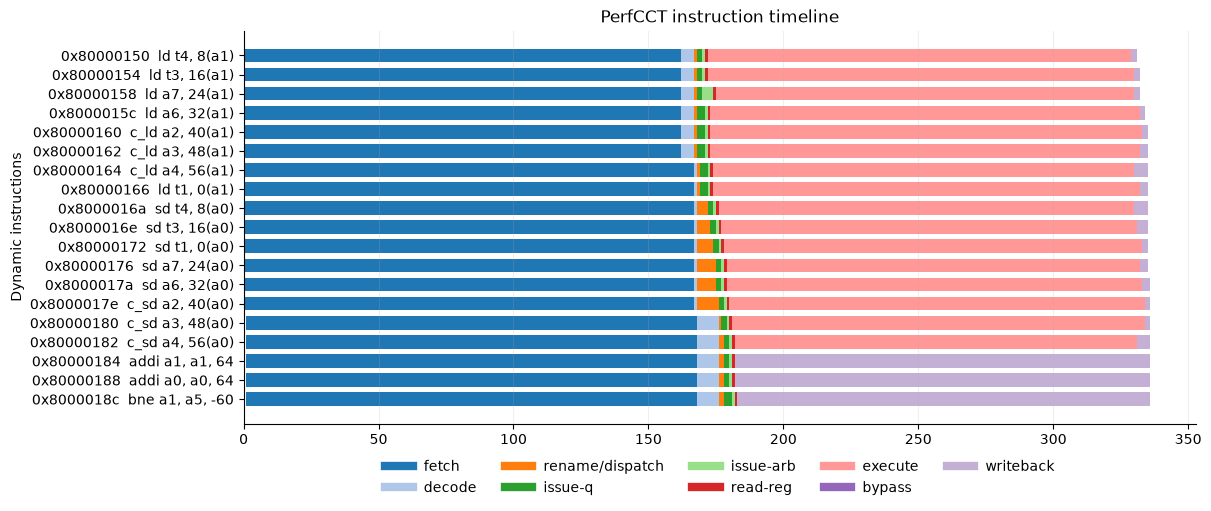

In [102]:
from gem5_tutorial_utils import plot_perfcct_timeline

# 使用 perfcct 数据库绘制指定 PC 范围内的时钟周期的可视化时间轴
fig, timeline = plot_perfcct_timeline(
    DB,
    START_PC,
    END_PC,
    period=PERIOD,
    start_cycle=start_cycle,
    end_cycle=end_cycle,
)
plt.show()

可以观察到 load store 指令的执行延迟极高，与 Topdown 中的结果呼应，由于没有打开预取，指令总是发生 cache miss，总是需要从 DDR 中获取数据，带来高额的 miss latency 开销，接下来我们看看开启 kmhv3 预取后的情形。

## 4. 开启 KMHv3 默认预取

In [103]:
%%bash
set -euo pipefail
source ../env.sh

RUN="$WORK_DIR/04-gem5/03-perf/kmhv3-default"
mkdir -p "$RUN"
rm -rf "$RUN/m5out"
rm -f "$RUN/perfcct.db"
GEM5_BIN=$(get_asset gem5-precompile/gem5.fast)
MEMCPY=$(get_asset workload/gem5-memcpy-riscv64-xs.bin)
export LD_LIBRARY_PATH="$(get_asset gem5-precompile):${LD_LIBRARY_PATH:-}"
export GCBV_REF_SO=$(get_asset gem5-precompile/riscv64-nemu-interpreter-so)
cd "$GEM5_HOME"

# 去掉 --no-pf 参数，使用默认的 kmhv3.py 配置文件运行仿真
"$GEM5_BIN" --outdir="$RUN/m5out" \
  "$GEM5_HOME/configs/example/kmhv3.py" \
  --raw-cpt --generic-rv-cpt="$MEMCPY" \
  --enable-arch-db --arch-db-dump-lifetime \
  --arch-db-file="$RUN/perfcct.db" \
  2>&1 | tee "$RUN/run.log" >/dev/null

tr '\r' '\n' < "$RUN/run.log" | tail -n 20

build/RISCV/mem/physical.cc:580: info: copying /nfs/home/lixin/myworkspace/bootcamp/assets/workload/gem5-memcpy-riscv64-xs.bin to pmem 0x768b92000000
build/RISCV/mem/physical.cc:610: info: First 4 bytes are 0x93 0x0 0x0 0x0
build/RISCV/sim/system.cc:561: info: Restored from Xiangshan RISC-V Checkpoint
**** REAL SIMULATION ****
build/RISCV/sim/simulate.cc:194: info: Entering event queue @ 0.  Starting simulation...
build/RISCV/dev/serial/uartlite.cc:86: warn: Write to other uartlite addr 12 is not implemented
build/RISCV/cpu/o3/issue_queue.cc:529: warn: Tt's should not happen on classic cache, it may be wrong delay of load wake or missed loadcancel in lsq
memcpy size: 512 KiB

memcpy cycles: 62559

memcpy payload bandwidth: 23977.37 MiB/s

memcpy read+write traffic: 47954.73 MiB/s

memcpy checksum: 0xffffffffffffffff

MEMCPY_RESULT bytes=524288 cycles=62559 payload_mib_s=23977.37 traffic_mib_s=47954.73 checksum=0xffffffffffffffff
Exiting @ tick 158449059 because m5_exit instruction enco

### memcpy 带宽对比

,cycles,payload_mib_s,traffic_mib_s,speedup
configuration,,,,
No prefetch,295505,5076.06,10152.11,1.00
KMHv3 default,62559,23977.37,47954.73,4.72


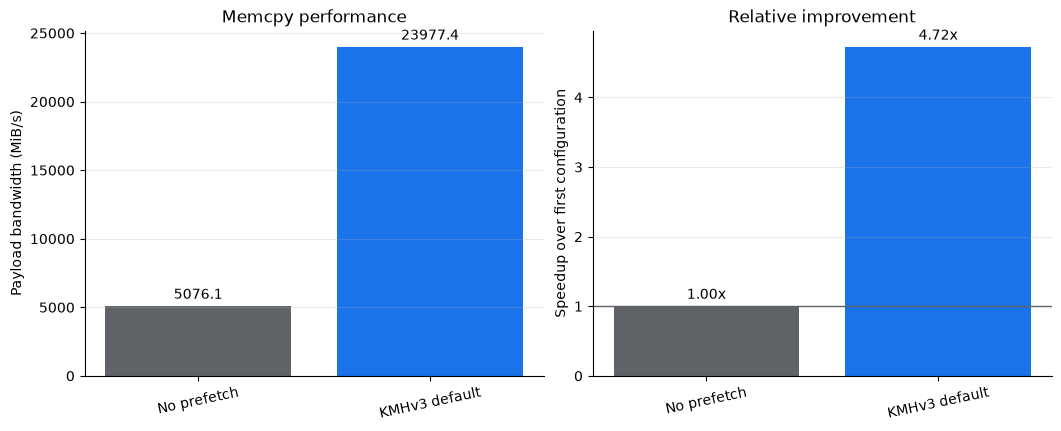

In [104]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()
if not (ROOT / "GEM5").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "04-gem5"))

from gem5_tutorial_utils import plot_memcpy_bandwidth
fig, results = plot_memcpy_bandwidth({
    "No prefetch": ROOT / "work/04-gem5/03-perf/no-prefetch/run.log",
    "KMHv3 default": ROOT / "work/04-gem5/03-perf/kmhv3-default/run.log",
})
display(results[["cycles", "payload_mib_s", "traffic_mib_s", "speedup"]])
plt.show()

### 关键 load 的 gap 对比

这里我们观察访存指令的两个指标：

- **execute inner-gap**：一条 load 的执行延迟；
- **commit inter-gap**：当前 load 的 rob 提交时刻减去前一条动态指令的 rob 提交时刻。

,execute_inner_gap,commit_inter_gap
configuration,,
KMHv3 default,15.92,1.00
No prefetch,170.15,8.42


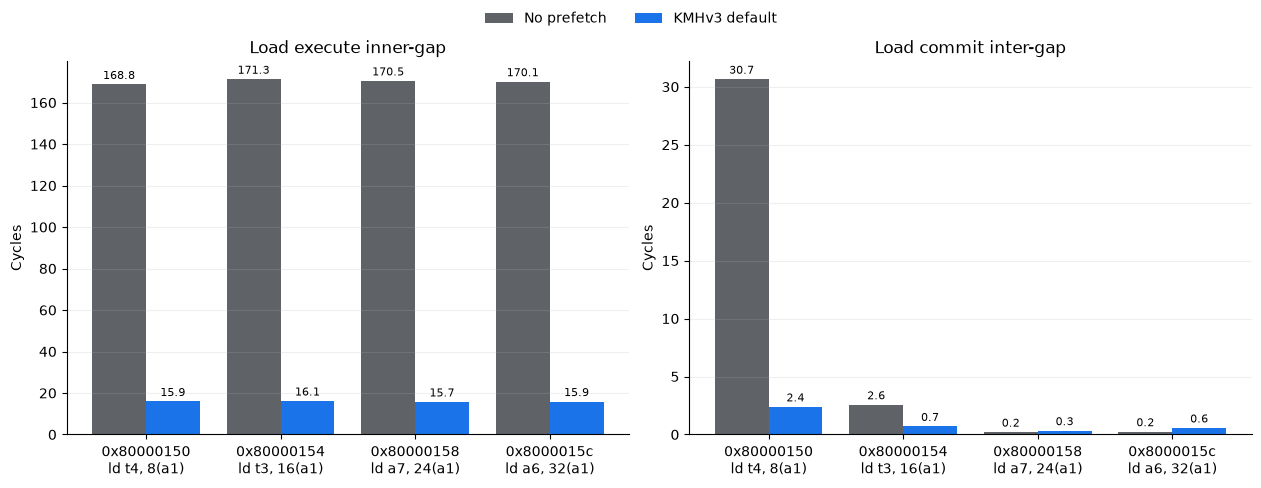

In [105]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()
if not (ROOT / "GEM5").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "04-gem5"))

from gem5_tutorial_utils import cpu_clock_period, plot_load_gap_comparison

PERIOD = cpu_clock_period(ROOT / "work/04-gem5/03-perf/no-prefetch-perfcct/m5out/stats.txt")
fig, gaps = plot_load_gap_comparison({
    "No prefetch": ROOT / "work/04-gem5/03-perf/no-prefetch-perfcct/perfcct.db",
    "KMHv3 default": ROOT / "work/04-gem5/03-perf/kmhv3-default/perfcct.db",
}, 0x80000140, 0x80000192, period=PERIOD)
display(
    gaps.groupby("configuration")[["execute_inner_gap", "commit_inter_gap"]]
    .mean().round(2)
)
plt.show()

预取开启后，如果数据更早到达缓存，load 的 execute inner-gap 会先缩短，流水线提交停顿随之减少，最终反映为更高的 memcpy 带宽。

## 5. 开启预取后的 Instruction timeline

最后用 KMHv3 默认预取运行生成的 PerfCCT 数据，展示 memcpy 热点循环某次执行下的指令 timeline。

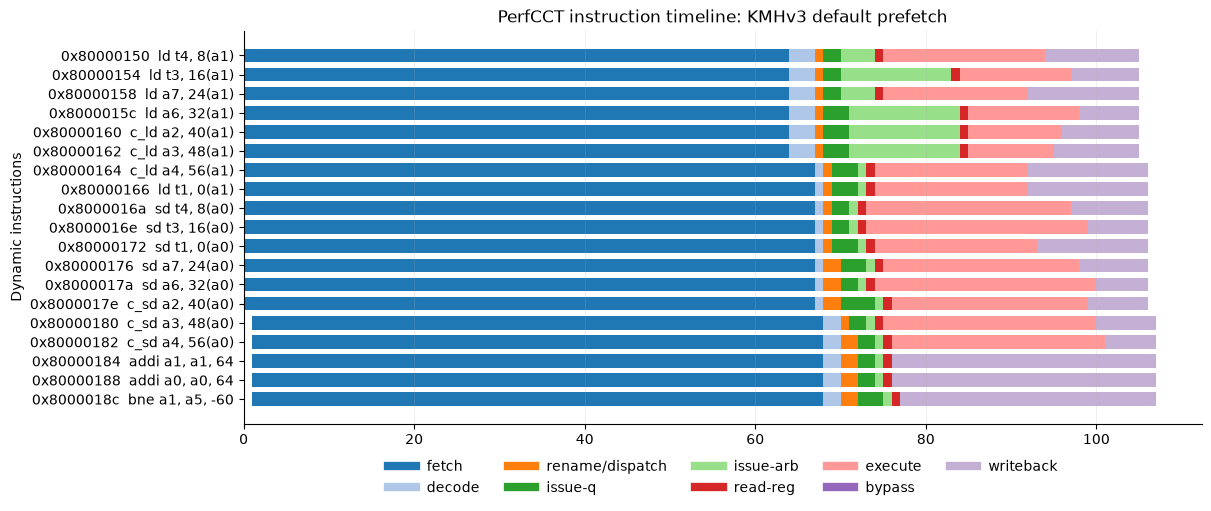

In [106]:
from gem5_tutorial_utils import plot_perfcct_timeline

fig, _ = plot_perfcct_timeline(
    ROOT / "work/04-gem5/03-perf/kmhv3-default/perfcct.db",
    START_PC,
    END_PC,
)
fig.axes[0].set_title("PerfCCT instruction timeline: KMHv3 default prefetch")
plt.show()

与关闭预取时的 timeline 相比，横轴覆盖的周期数明显减少，load 的 execute 色块也显著缩短。预取把数据更早带入缓存，因而降低了关键访存指令的执行等待，并最终提升 memcpy 带宽。

# 04-Case study：给 GEM5 增加 L2 next-line prefetcher

这一节展示如何把一个新的预取部件接入 GEM5。代码已经作为提交 `8eecd224437707c4c5199bcd49ceca4a15ef8e4a` 合入 XS-GEM5，现场不 apply patch，也不重新编译。

我们阅读三处关键代码：预取地址如何生成、SimObject 如何注册、`kmhv3.py` 如何提供独立开关。然后用同一个预编译 `gem5.fast` 运行实验。

## 1. 阅读已经合入的实现

In [12]:
%%bash
source ../env.sh

COMMIT=8eecd224437707c4c5199bcd49ceca4a15ef8e4a
git -C "$GEM5_HOME" show --stat --oneline "$COMMIT"

printf '\n1) Core next-line algorithm:\n'
git -C "$GEM5_HOME" show "$COMMIT:src/mem/cache/prefetch/next_line.cc" \
  | sed -n '/NextLine::calculatePrefetch/,/^}/p'

printf '\n2) SimObject registration:\n'
git -C "$GEM5_HOME" show "$COMMIT:src/mem/cache/prefetch/Prefetcher.py" \
  | sed -n '489,495p'

printf '\n3) kmhv3.py switch:\n'
git -C "$GEM5_HOME" show "$COMMIT:configs/example/kmhv3.py" \
  | sed -n '205,215p' 

8eecd22 mem-cache: Add tutorial L2 next-line prefetcher
 configs/common/Options.py            |  4 +++
 configs/common/PrefetcherConfig.py   |  9 +++++-
 configs/common/xiangshan.py          |  8 ++++--
 configs/example/kmhv3.py             | 11 ++++++++
 src/mem/Request.py                   |  1 +
 src/mem/cache/prefetch/Prefetcher.py |  7 +++++
 src/mem/cache/prefetch/SConscript    |  3 +-
 src/mem/cache/prefetch/next_line.cc  | 53 ++++++++++++++++++++++++++++++++++
 src/mem/cache/prefetch/next_line.hh  | 55 ++++++++++++++++++++++++++++++++++++
 9 files changed, 147 insertions(+), 4 deletions(-)

1) Core next-line algorithm:
NextLine::calculatePrefetch(const PrefetchInfo &pfi,
                            std::vector<AddrPriority> &addresses)
{
    addresses.emplace_back(blockAddress(pfi.getAddr()) + blkSize, 0,
                           PrefetchSourceType::NextLine);
}

2) SimObject registration:
class NextLinePrefetcher(QueuedPrefetcher):
    type = 'NextLinePrefetcher'
    cxx_cla

核心算法是把当前地址对齐到 cache line，再请求下一条 line。`NextLinePrefetcher` 注册为一个 `QueuedPrefetcher` SimObject；使用 `l2_wrapper_hwp_type` 将 `NextLinePrefetcher` 挂载到 L2 cache 中 `--l2-next-line-only` 开关表示仅开启 `NextLinePrefetcher`

## 2. 用预编译 GEM5 运行 next-line memcpy

In [13]:
%%bash
set -euo pipefail
source ../env.sh

RUN="$WORK_DIR/04-gem5/04-case-study-prefetcher/l2-next-line"
mkdir -p "$RUN"
rm -rf "$RUN/m5out"
rm -f "$RUN/perfcct.db"
GEM5_BIN=$(get_asset gem5-precompile/gem5.fast)
MEMCPY=$(get_asset workload/gem5-memcpy-riscv64-xs.bin)
export LD_LIBRARY_PATH="$(get_asset gem5-precompile):${LD_LIBRARY_PATH:-}"
export GCBV_REF_SO=$(get_asset gem5-precompile/riscv64-nemu-interpreter-so)
cd "$GEM5_HOME"

# 使用 --l2-next-line-only 参数仅启用 L2 Cache 的 Next-Line Prefetcher
"$GEM5_BIN" --outdir="$RUN/m5out" \
  "$GEM5_HOME/configs/example/kmhv3.py" \
  --raw-cpt --generic-rv-cpt="$MEMCPY" \
  --l2-next-line-only \
  --enable-arch-db --arch-db-dump-lifetime \
  --arch-db-file="$RUN/perfcct.db" \
  2>&1 | tee "$RUN/run.log" >/dev/null

cat "$RUN/run.log" | tail -n 20

Registering probe listeners for Prefetcher system.l2_wrappers.slices2.inner_cache.prefetcher
system.l2_wrappers.slices2.inner_cache.prefetcher addTLB system.cpu.mmu.dtb
Registering inner cache accessor for L2CacheSlice system.l2_wrappers.slices3
Registering probe listeners for Prefetcher system.l2_wrappers.slices3.inner_cache.prefetcher
system.l2_wrappers.slices3.inner_cache.prefetcher addTLB system.cpu.mmu.dtb
build/RISCV/mem/physical.cc:509: warn: Unserializing physical memory from file /nfs/home/lixin/myworkspace/bootcamp/assets/workload/gem5-memcpy-riscv64-xs.bin
build/RISCV/mem/physical.cc:580: info: copying /nfs/home/lixin/myworkspace/bootcamp/assets/workload/gem5-memcpy-riscv64-xs.bin to pmem 0x70c0ab400000
build/RISCV/mem/physical.cc:610: info: First 4 bytes are 0x93 0x0 0x0 0x0
build/RISCV/sim/system.cc:561: info: Restored from Xiangshan RISC-V Checkpoint
**** REAL SIMULATION ****
build/RISCV/sim/simulate.cc:194: info: Entering event queue @ 0.  Starting simulation...
build/RI

## 3. 带宽：无预取 baseline 与 L2 next-line

,cycles,payload_mib_s,speedup
configuration,,,
No prefetch,295505,5076.06,1.000000
L2 next-line,249907,6002.23,1.182458


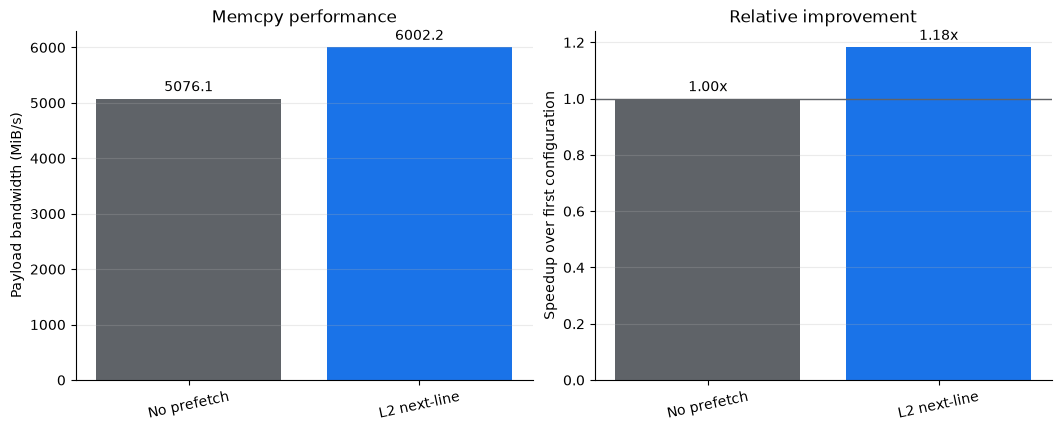

In [14]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()
if not (ROOT / "GEM5").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "04-gem5"))

from gem5_tutorial_utils import plot_memcpy_bandwidth
fig, results = plot_memcpy_bandwidth({
    "No prefetch": ROOT / "work/04-gem5/03-perf/no-prefetch/run.log",
    "L2 next-line": ROOT / "work/04-gem5/04-case-study-prefetcher/l2-next-line/run.log",
})
display(results[["cycles", "payload_mib_s", "speedup"]])
plt.show()

## 4. 关键 load 的 gap

沿用 03 的相同定义，我们观察 load 指令的执行延迟和 commit gap 是否获得了改善。

,execute_inner_gap,commit_inter_gap
configuration,,
L2 next-line,142.02,7.03
No prefetch,170.15,8.42


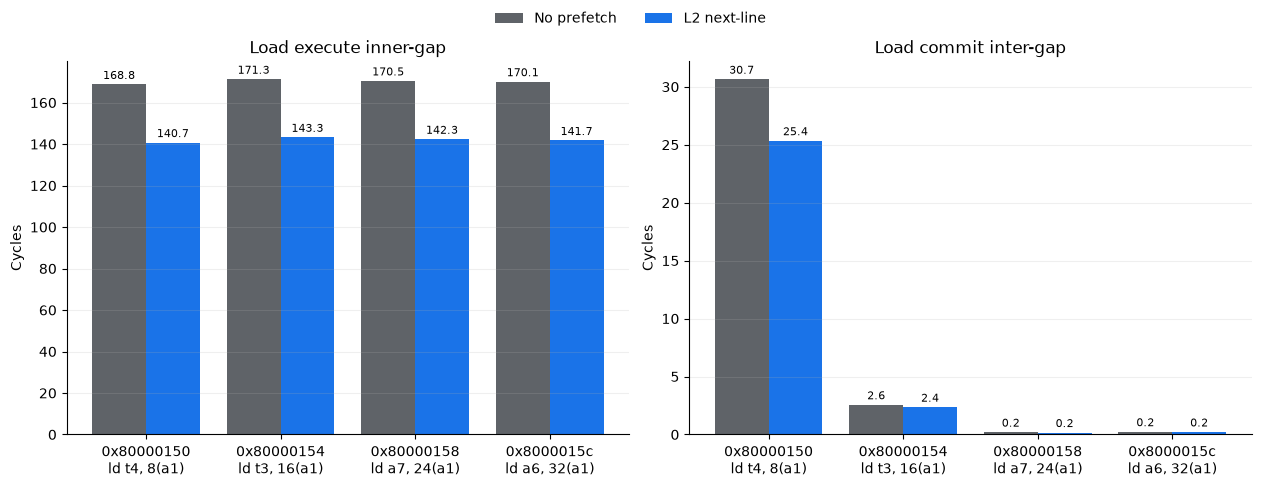

In [15]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()
if not (ROOT / "GEM5").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "04-gem5"))

from gem5_tutorial_utils import cpu_clock_period, plot_load_gap_comparison

PERIOD = cpu_clock_period(ROOT / "work/04-gem5/03-perf/no-prefetch-perfcct/m5out/stats.txt")
fig, gaps = plot_load_gap_comparison({
    "No prefetch": ROOT / "work/04-gem5/03-perf/no-prefetch-perfcct/perfcct.db",
    "L2 next-line": ROOT / "work/04-gem5/04-case-study-prefetcher/l2-next-line/perfcct.db",
}, 0x80000140, 0x80000192, period=PERIOD)
display(
    gaps.groupby("configuration")[["execute_inner_gap", "commit_inter_gap"]]
    .mean().round(2)
)
plt.show()

这个 case study 展示了一个最小的基于 XS-GEM5 的研究示例：从 memory-bound 现象提出一个最小预取策略，给 GEM5 增加新的功能，再用带宽、gap等指标验证设计的效果。